# Linear Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
diabetes = load_diabetes()

df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

df["Target"] = diabetes.target

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  Target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
None

Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
Target    0
dtype: int64

Statistical Summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


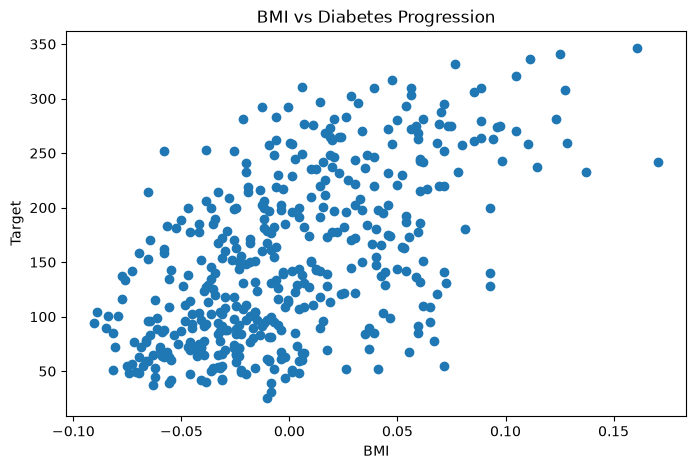

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(df["bmi"], df["Target"])

plt.title("BMI vs Diabetes Progression")
plt.xlabel("BMI")
plt.ylabel("Target")
plt.show()

In [5]:
X = df.drop("Target", axis=1)
y = df["Target"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (442, 10)
Target Shape: (442,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 353
Testing Samples: 89


In [7]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Linear Regression Model Trained Successfully!
Intercept: 151.34560453985995
Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]


In [8]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Values": y_test.values,
    "Predicted Values": y_pred.round(2)
})

results.head(10)

,Actual Values,Predicted Values
0,219.0,139.55
1,70.0,179.52
2,202.0,134.04
3,230.0,291.42
4,111.0,123.79
5,84.0,92.17
6,242.0,258.23
7,272.0,181.34
8,94.0,90.22
9,96.0,108.63


In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Evaluation")
print("-" * 40)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 3))
print("Model Accuracy (R2 Score):", round(r2 * 100, 2), "%")

Linear Regression Model Evaluation
----------------------------------------
Mean Absolute Error (MAE): 42.79
Mean Squared Error (MSE): 2900.19
Root Mean Squared Error (RMSE): 53.85
R2 Score: 0.453
Model Accuracy (R2 Score): 45.26 %


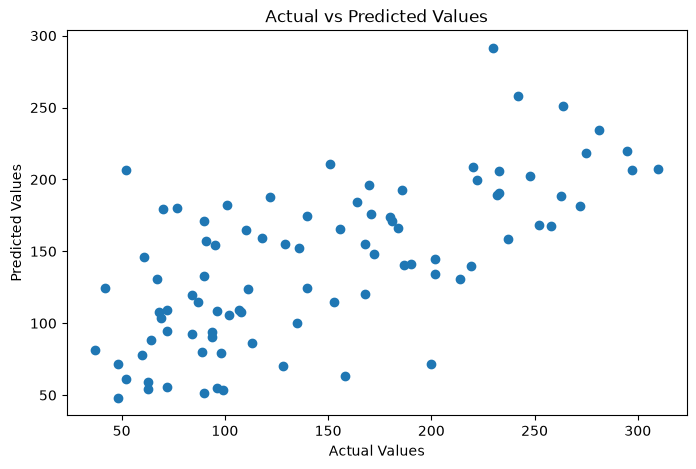

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")

plt.show()

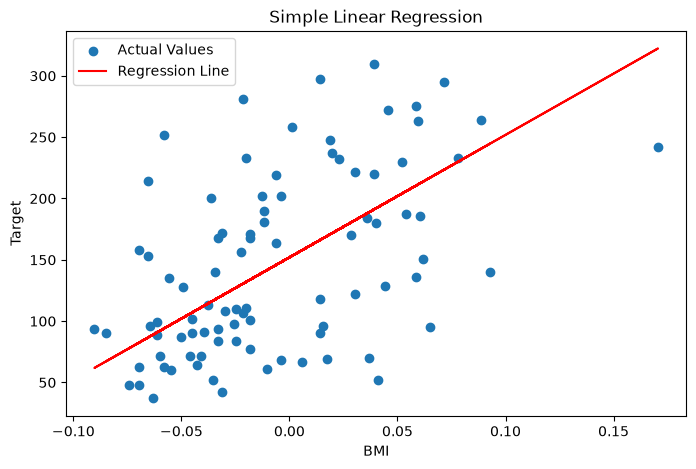

In [11]:
X_bmi = df[["bmi"]]
y_bmi = df["Target"]

X_train_bmi, X_test_bmi, y_train_bmi, y_test_bmi = train_test_split(
    X_bmi, y_bmi,
    test_size=0.2,
    random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_bmi, y_train_bmi)

y_pred_bmi = simple_model.predict(X_test_bmi)

plt.figure(figsize=(8, 5))

plt.scatter(X_test_bmi["bmi"], y_test_bmi, label="Actual Values")
plt.plot(
    X_test_bmi["bmi"],
    y_pred_bmi,
    color="red",
    label="Regression Line"
)

plt.xlabel("BMI")
plt.ylabel("Target")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [12]:
print("=" * 45)
print("LINEAR REGRESSION PROJECT")
print("=" * 45)

print("Dataset: Diabetes Dataset")
print("Total Samples:", len(df))
print("Total Features:", X.shape[1])
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("R2 Score:", round(r2, 3))
print("\nModel trained and evaluated successfully!")

LINEAR REGRESSION PROJECT
Dataset: Diabetes Dataset
Total Samples: 442
Total Features: 10
Training Samples: 353
Testing Samples: 89
R2 Score: 0.453

Model trained and evaluated successfully!
